# Tổng hợp phát hiện — Calibration: hiệu chỉnh mô hình nhân quả đuôi (60 mã)

Gom các phát hiện từ `01_hyperparameters`, `02_factor_adjusted_ease`, `03_extremal_granger`, `04_nonlinear_factor_autoencoder`.

| # | Phát hiện | Hệ quả |
|---|---|---|
| 1 | GJR/EGARCH tốt hơn theo BIC ở 42/60 mã nhưng kết quả đuôi thay đổi ít (đồng thuận 0,90); $K = 1$ nhân tố; chọn $k = \lfloor n^{0,35}\rfloor = 14$ (tối ưu mô phỏng) | Siêu tham số có cơ sở dữ liệu |
| 2 | Khử nhân tố trước EASE là bắt buộc (SID 0,028 → 0,011–0,014); với 60 mã các cách khử ngang nhau, hệ số có điều kiện còn lệch theo tải | Quy trình EASE hiệu chỉnh |
| 3 | Sau khử nhân tố, phụ thuộc đuôi còn lại nằm trong các ngành hẹp (ngân hàng, thép, chứng khoán, phân bón, thuỷ sản, Vingroup) | Cấu trúc ngành, chiều chỉ là gợi ý |
| 4 | Granger trong đuôi: trễ 1 có 131 cặp qua FDR, chủ yếu đổ vào mã vừa và nhỏ; theo ngưỡng mô phỏng nghiêm chỉ 7 cặp (nhiễu ~3,5) | Nghi trễ do thanh khoản, cần kiểm soát |
| 5 | Hệ số tải bất đối xứng ở 17/60 mã; AE hệ số tải phi tuyến không tăng $R^2$ nhưng giảm 28% độ lệch đuôi của phần dư ở các mã đó ($p$ = 0,003); EASE gần như không đổi | Khử nhân tố bằng AE phi tuyến |

## 0. Thiết lập

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "calibration"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

from scipy import stats
TAB = ROOT / "report" / "table"
def read(name, folder=FOLDER, **kw):
    path = TAB / folder / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Thiếu {path.relative_to(ROOT)} — chạy các notebook chi tiết của giai đoạn trước.")
    return pd.read_csv(path, encoding="utf-8-sig", **kw)
P = len(SYMBOLS); OFF = ~np.eye(P, dtype=bool)
SEC = np.array([U.SECTOR[s] for s in SYMBOLS])
def sector_blocks(M):
    """Trung bình hệ số theo khối ngành (ngành nguồn × ngành đích), bỏ đường chéo."""
    rows = [(SEC[i], SEC[j], M[i, j]) for i in range(P) for j in range(P) if i != j and not np.isnan(M[i, j])]
    d = pd.DataFrame(rows, columns=["nguon", "dich", "v"]).groupby(["nguon", "dich"]).v.mean().unstack()
    return d.reindex(index=U.SECTORS, columns=U.SECTORS)

import calibration as C
z = pd.read_parquet(ROOT / "data" / "processed" / "garch_std_resid_market.parquet")[SYMBOLS]
n = len(z); KC = CT.default_k(n, 0.35)
print(f"n = {n}, k hiệu chỉnh = {KC}")

n = 2103, k hiệu chỉnh = 14


## Phát hiện 1 — Siêu tham số chọn từ dữ liệu

**Tính gì:** (a) ΔBIC của 4 dạng GARCH; (b) Ahn–Horenstein $\mathrm{ER}(k) = \mu_k/\mu_{k+1}$ cho số nhân tố; (c) SID của EASE (có điều kiện thị trường) theo $\nu$ trên dữ liệu
mô phỏng khớp với dữ liệu thật (một nhân tố + DAG thưa).

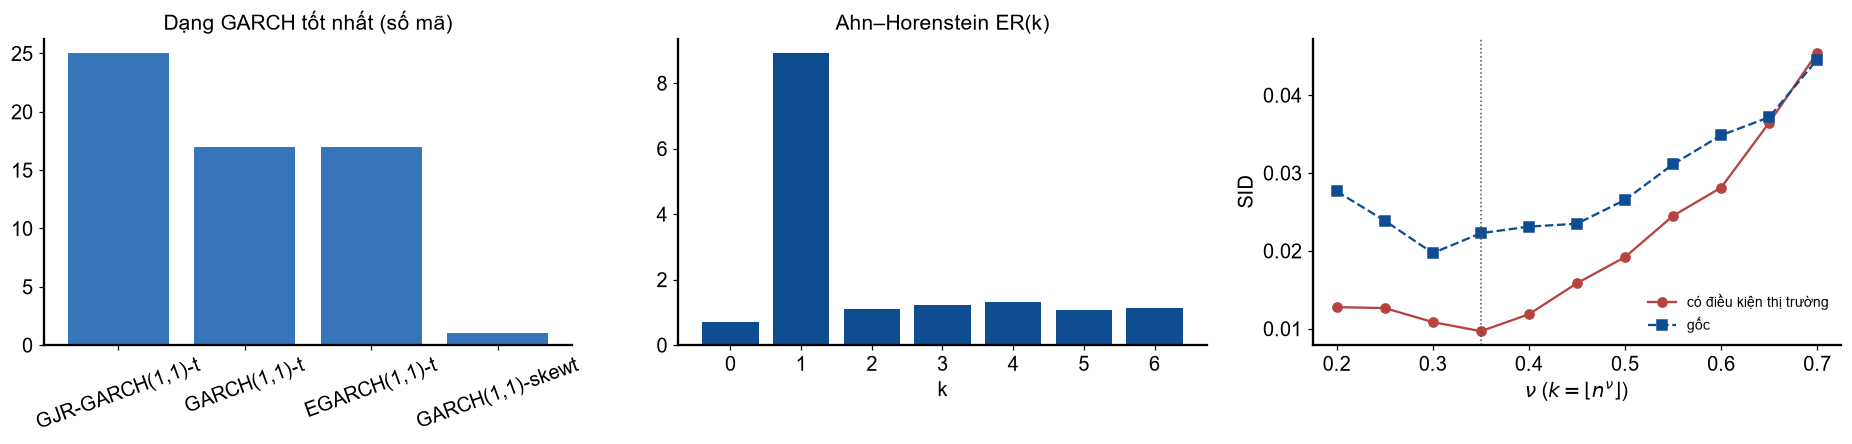

In [2]:
dbic = read("01_garch_dbic", index_col=0)
ah = read("01_ahn_horenstein", index_col=0)
ks = read("01_k_calibrated_sim").groupby(["phuong_phap", "nu"]).SID.mean().unstack(0)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
best = dbic.idxmin(axis=1).value_counts()
axes[0].bar(best.index, best.values, color=PAL["blue_secondary"]); axes[0].set_title("Dạng GARCH tốt nhất (số mã)"); axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(ah.index, ah.ER, color=PAL["blue_main"]); axes[1].set_xlabel("k"); axes[1].set_title("Ahn–Horenstein ER(k)")
axes[2].plot(ks.index, ks["dieu_kien"], "o-", color=PAL["red_strong"], label="có điều kiện thị trường")
axes[2].plot(ks.index, ks["tho"], "s--", color=PAL["blue_main"], label="gốc")
axes[2].axvline(0.35, color=PAL["gray_dark"], ls=":", lw=1); axes[2].set_xlabel(r"$\nu$ ($k=\lfloor n^\nu\rfloor$)"); axes[2].set_ylabel("SID"); axes[2].legend(fontsize=9)
U.finalize_figure(fig, "finding_1_hyperparameters", folder=FOLDER); plt.show()

### Phân tích
- GJR-GARCH-t thắng ở 25 mã, EGARCH-t ở 17 (8/14 mã bất động sản), GARCH-t ở 17; nhưng thứ tự EASE với dạng tốt nhất đồng thuận 0,90 với GARCH-t — lựa chọn GARCH **ít quan trọng** cho kết quả đuôi.
- ER đạt cực đại rõ ở $k = 1$ (8,91): một nhân tố thị trường chiếm 35% phương sai.
- SID thấp nhất ở $\nu = 0{,}35$ (0,010) với EASE có điều kiện; EASE có điều kiện tốt hơn EASE gốc ở mọi $\nu$. Chọn $\nu = 0{,}35$ ($k = 14$) — giữ nguyên lựa chọn của giai đoạn 20 mã.

## Phát hiện 2 — Khử nhân tố trước EASE là bắt buộc

**Tính gì:** 5 phương pháp (gốc; loại thị trường LOO; LOO + ngành; PCA một nhân tố trên tương quan Kendall; hệ số có điều kiện thị trường
$\tilde\Psi = \tfrac12 + \tfrac12(\Psi^E - b)/(1 - b)$) trên 60 bộ dữ liệu dưới $H_0$ (không cạnh) và 60 bộ dưới $H_1$ (cạnh thưa).

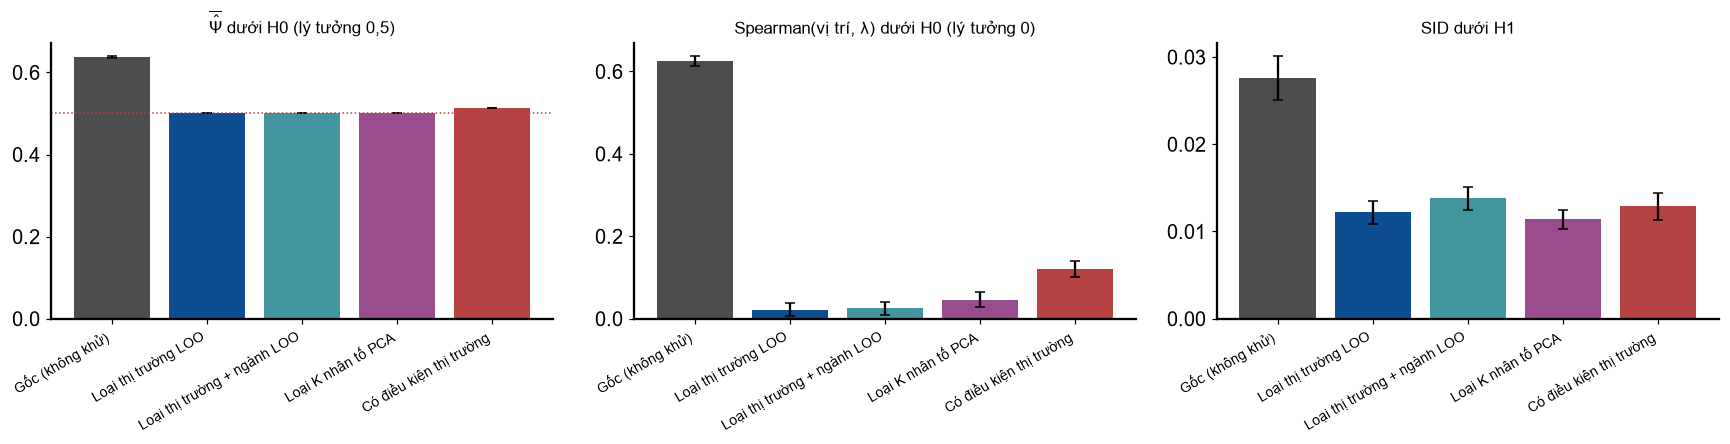

,psi_TB,cung_nganh,khac_nganh,rho_lambda
phuong_phap,,,,
Gốc (không khử),0.667,0.703,0.661,0.638
Loại thị trường LOO,0.544,0.578,0.539,0.357
Loại thị trường + ngành LOO,0.539,0.576,0.533,0.301
Loại K nhân tố PCA,0.545,0.578,0.540,0.322
Có điều kiện thị trường,0.552,0.603,0.544,0.517


In [3]:
sim = read("02_deconfounding_sim")
METH = list(C.DECONF_METHODS); names = [C.DECONF_LABELS[m] for m in METH]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
cm = [PAL["gray_dark"], PAL["blue_main"], PAL["teal"], PAL["violet"], PAL["red_strong"]]
for ax, (col, h, title, ref) in zip(axes, [("psi_TB", "H0", r"$\overline{\hat\Psi}$ dưới H0 (lý tưởng 0,5)", 0.5),
                                           ("rho_lambda", "H0", "Spearman(vị trí, λ) dưới H0 (lý tưởng 0)", 0),
                                           ("SID", "H1", "SID dưới H1", None)]):
    d = sim[sim.gia_thuyet == h].groupby("phuong_phap")[col].agg(["mean", "sem"]).reindex(METH)
    ax.bar(range(5), d["mean"], yerr=d["sem"], color=cm, capsize=3)
    if ref is not None:
        ax.axhline(ref, color=PAL["red_strong"], ls=":", lw=1)
    ax.set_xticks(range(5), names, rotation=30, ha="right", fontsize=9); ax.set_title(title, fontsize=11)
U.finalize_figure(fig, "finding_2_deconfounding", folder=FOLDER); plt.show()
read("02_real_methods", index_col=0)[["psi_TB", "cung_nganh", "khac_nganh", "rho_lambda"]].round(3)

### Phân tích
- Không khử: thứ tự giả theo tải (ρ = 0,63 dưới $H_0$; 0,64 trên dữ liệu thật), SID 0,028 dưới $H_1$. Mọi phương pháp khử đưa $\overline{\hat\Psi}$ về 0,50–0,52.
- Với 60 mã, **LOO, LOO+ngành và PCA** xoá thứ tự theo tải gần hết (ρ = 0,02–0,05) và cho SID 0,011–0,014, ngang hệ số có điều kiện (0,013) — chênh lệch trong ~1 sai số chuẩn.
  **Hệ số có điều kiện không còn tốt nhất** như với 20 mã và giữ độ lệch theo tải (ρ = 0,12). Lý do: nhân tố ước lượng từ 60 mã chính xác hơn, ngành nhiều mã hơn nên LOO ngành bớt nhiễu.
- Trên dữ liệu thật mọi phương pháp còn ρ = 0,30–0,52 với tải, cao hơn mức dưới $H_0$ — dữ liệu có cấu trúc **ngoài** một nhân tố (ngành hẹp).

## Phát hiện 3 — Phụ thuộc đuôi còn lại nằm trong ngành

**Tính gì:** ma trận hệ số có điều kiện thị trường $\tilde\Psi$ ($k = 14$) trung bình theo khối ngành; các hệ số lớn nhất và khoảng bootstrap khối 90% của chúng.

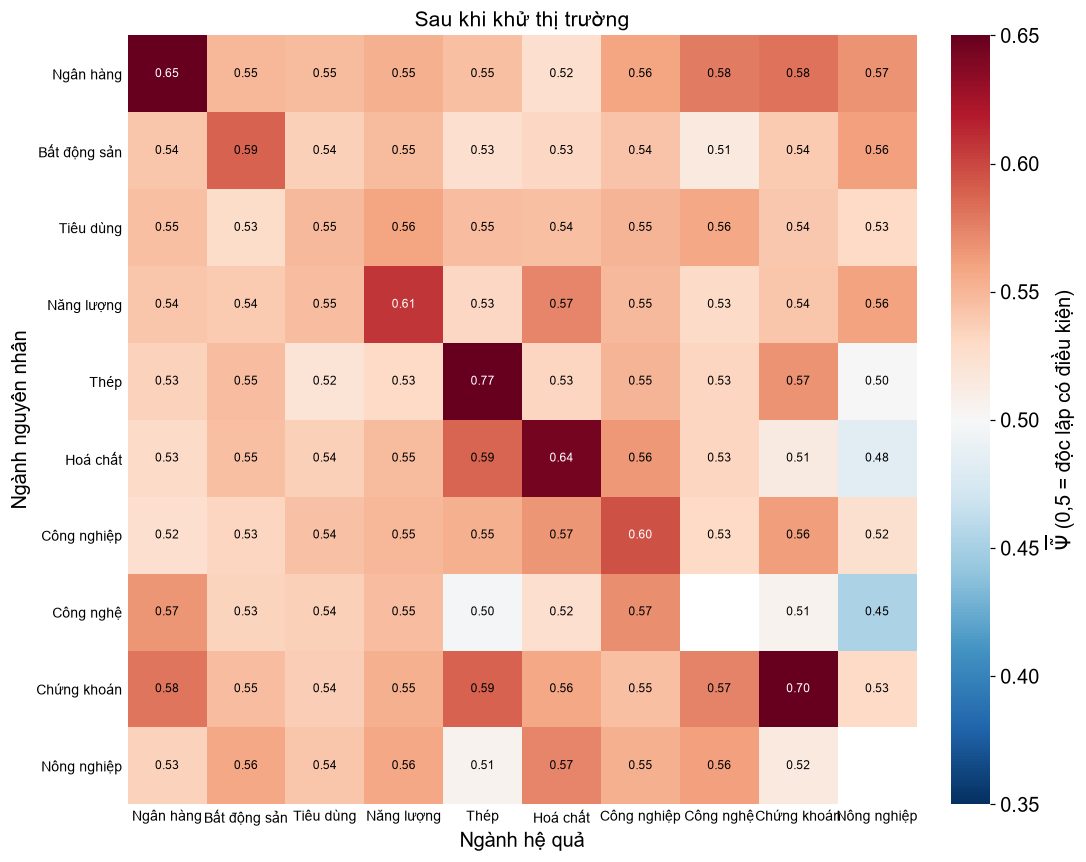

,nganh,psi_dk,q05,q95,D,D_q05,D_q95,co_chieu
cap,,,,,,,,
MBB→TCB,Ngân hàng → Ngân hàng,0.858,0.780,0.912,0.084,-0.010,0.130,False
HSG→NKG,Thép → Thép,0.855,0.738,0.908,0.068,-0.057,0.173,False
SSI→HCM,Chứng khoán → Chứng khoán,0.841,0.794,0.910,0.041,-0.029,0.125,False
VHC→ANV,Tiêu dùng → Tiêu dùng,0.836,0.761,0.896,0.181,0.062,0.284,True
CTG→MBB,Ngân hàng → Ngân hàng,0.829,0.768,0.905,0.030,-0.082,0.098,False
DCM→DPM,Hoá chất → Hoá chất,0.827,0.774,0.909,0.072,-0.037,0.152,False
HPG→HSG,Thép → Thép,0.819,0.685,0.873,0.129,0.018,0.221,True
MBB→VPB,Ngân hàng → Ngân hàng,0.815,0.720,0.865,0.136,0.011,0.228,True
VHM→VIC,Bất động sản → Bất động sản,0.808,0.705,0.883,0.041,-0.044,0.137,False


In [4]:
Madj = C.adjusted_tail_coef_matrix(z, k=KC)["adj"]
blk = sector_blocks(Madj.values)
fig, ax = plt.subplots(figsize=(10, 8))
U.make_heatmap(ax, blk, cmap="RdBu_r", vmin=0.35, vmax=0.65, fmt="{:.2f}", annot_fontsize=8, tick_fontsize=9,
               cbar_label=r"$\overline{\tilde\Psi}$ (0,5 = độc lập có điều kiện)", title="Sau khi khử thị trường")
ax.set_xlabel("Ngành hệ quả"); ax.set_ylabel("Ngành nguyên nhân")
U.finalize_figure(fig, "finding_3_residual_sectors", folder=FOLDER); plt.show()
read("02_top_conditional", index_col=0)[["nganh", "psi_dk", "q05", "q95", "D", "D_q05", "D_q95", "co_chieu"]].round(3)

### Phân tích
- Sau khi khử thị trường, các khối đậm là **ngành hẹp**: 12/12 hệ số có điều kiện lớn nhất đều cùng ngành — MBB→TCB 0,86, HSG→NKG 0,86, SSI→HCM 0,84, VHC→ANV 0,84 (thuỷ sản),
  CTG→MBB, DCM→DPM 0,83, HPG→HSG, MBB→VPB, VHM→VIC 0,81.
- 5/12 cặp có bất đối xứng với khoảng bootstrap khối 90% không chứa 0: VHC → ANV (+0,18), HPG → NKG (+0,14), MBB → VPB (+0,14), HPG → HSG (+0,13), TCB → VPB (+0,10) —
  mã đầu ngành dẫn mã nhỏ cùng ngành. Chưa hiệu chỉnh đa so sánh: gợi ý, chưa phải bằng chứng. Gợi ý MBB → TCB của giai đoạn 20 mã không còn đứng vững trên hệ số có điều kiện.

## Phát hiện 4 — Granger trong đuôi: lan truyền cú sập theo ngày tồn tại nhưng thưa

**Tính gì:** $\hat\Gamma_{X\to Y}(p) = \frac{1}{|S|}\sum_{t\in S}\max_{h\le p}\tilde F_Y(Y_{t+h})$ trên các phiên $X_t$ cực trị (đuôi dưới) trong khi $Y_t$ và thị trường chưa cực trị,
so với mức nền $b$ (Bodik & Pasche 2024, arXiv:2407.09632). Kiểm tra kích thước kiểm định bằng mô phỏng $H_0$ (không có trễ), rồi dùng ngưỡng $\Delta$ ở phân vị 99,9% dưới $H_0$.

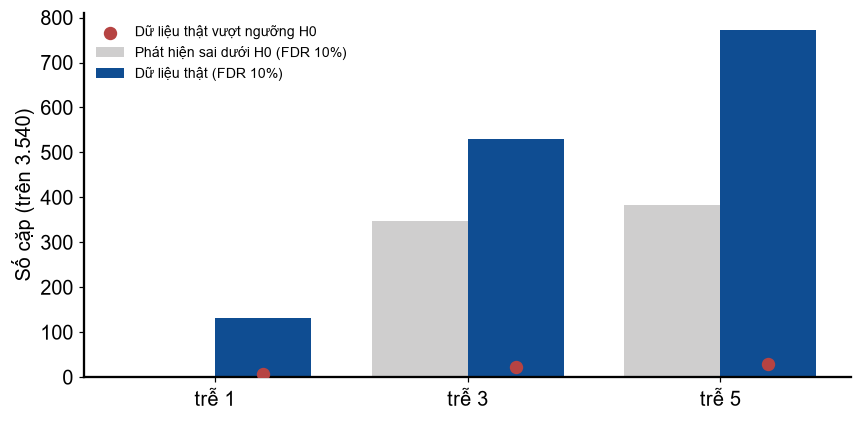

,tre,cause,effect,gamma,baseline,delta
4,1,DGC,HAG,0.784,0.372,0.411
1,1,GAS,VCI,0.747,0.378,0.369
6,1,CTD,DGW,0.743,0.385,0.359
3,1,PVT,HDG,0.721,0.369,0.352
0,1,VCB,PVT,0.712,0.375,0.338
5,1,VJC,DIG,0.700,0.366,0.334
2,1,PVT,DIG,0.696,0.366,0.329
27,3,SSI,TCM,0.907,0.679,0.227
9,3,DXG,VIC,0.887,0.675,0.211
21,3,HSG,DGC,0.897,0.686,0.211


In [5]:
size = read("03_size_check", index_col=[0, 1]).groupby(level=0).mean()
summ = read("03_granger_summary", index_col=0)
strong = read("03_granger_beyond_null")
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(3); w = 0.38
ax.bar(x - w / 2, size["so_cap_q<0,1"], w, color=PAL["neutral"], label="Phát hiện sai dưới H0 (FDR 10%)")
ax.bar(x + w / 2, summ.loc[["lower, p=1", "lower, p=3", "lower, p=5"], "so_cap_q<0,1"], w, color=PAL["blue_main"], label="Dữ liệu thật (FDR 10%)")
ax.scatter(x + w / 2, summ.loc[["lower, p=1", "lower, p=3", "lower, p=5"], "so_cap_vuot_nguong_H0"], color=PAL["red_strong"], zorder=3, s=60,
           label="Dữ liệu thật vượt ngưỡng H0")
ax.set_xticks(x, ["trễ 1", "trễ 3", "trễ 5"]); ax.set_ylabel("Số cặp (trên 3.540)"); ax.legend(fontsize=9)
U.finalize_figure(fig, "finding_4_extremal_granger", folder=FOLDER); plt.show()
strong[["tre", "cause", "effect", "gamma", "baseline", "delta"]].sort_values(["tre", "delta"], ascending=[True, False]).round(3)

### Phân tích
- Kiểm tra kích thước: trễ 1 hợp lệ (0 phát hiện sai qua FDR dưới $H_0$); trễ 3–5 bootstrap báo 305–395 phát hiện sai trên 3.540 cặp — không đáng tin.
- **Trễ 1:** 131 cặp qua FDR 10% (20 mã: 0), đích chủ yếu là mã vừa và nhỏ (DGC, HDG, PVT, HAG, CTS, KBC, DIG); nguồn hay gặp là năng lượng và ngân hàng. Mô hình $H_0$ không có tự tương quan
  nên chưa loại được **trễ do thanh khoản** (mã nhỏ phản ứng chậm) — cần kiểm soát trước khi gọi là lan truyền.
- Theo ngưỡng hiệu chỉnh bằng mô phỏng (99,9% $H_0$): 7 cặp ở trễ 1 (DGC→HAG, GAS→VCI, CTD→DGW, PVT→HDG, VCB→PVT, VJC→DIG, PVT→DIG; nhiễu kỳ vọng ~3,5), 22 ở trễ 3, 29 ở trễ 5;
  6 cặp lặp lại ở trễ 3 và 5 (DCM→TCB, PDR→TCB, KBC→VPB, SSI→TCM, VCI→FRT, PNJ→TCH). **GAS → VHM** của giai đoạn 20 mã không còn vượt ngưỡng.

## Phát hiện 5 — Khử nhân tố phi tuyến bằng autoencoder: phần dư sạch đuôi hơn, EASE gần như không đổi

**Tính gì:** trên bảng 60 mã (20 + 40 mã HOSE bổ sung), so PCA với autoencoder có nhân tố là danh mục tuyến tính và hệ số tải phi tuyến
$\hat x = W f + V\,\mathrm{ReLU}(A f + c) + b_D$ (theo Gu, Kelly & Xiu 2021; Spilak & Härdle 2022); phần dư tính ngoài mẫu bằng cross-fitting.
Thước đo đuôi: $\delta_i = \tfrac12\big(|\hat\Gamma^-_{m\to e_i} - \tfrac12| + |\hat\Gamma^+_{m\to e_i} - \tfrac12|\big)$, $m$ = trung bình đều 60 mã
(0 = phần dư không còn đồng sập/đồng tăng với thị trường).

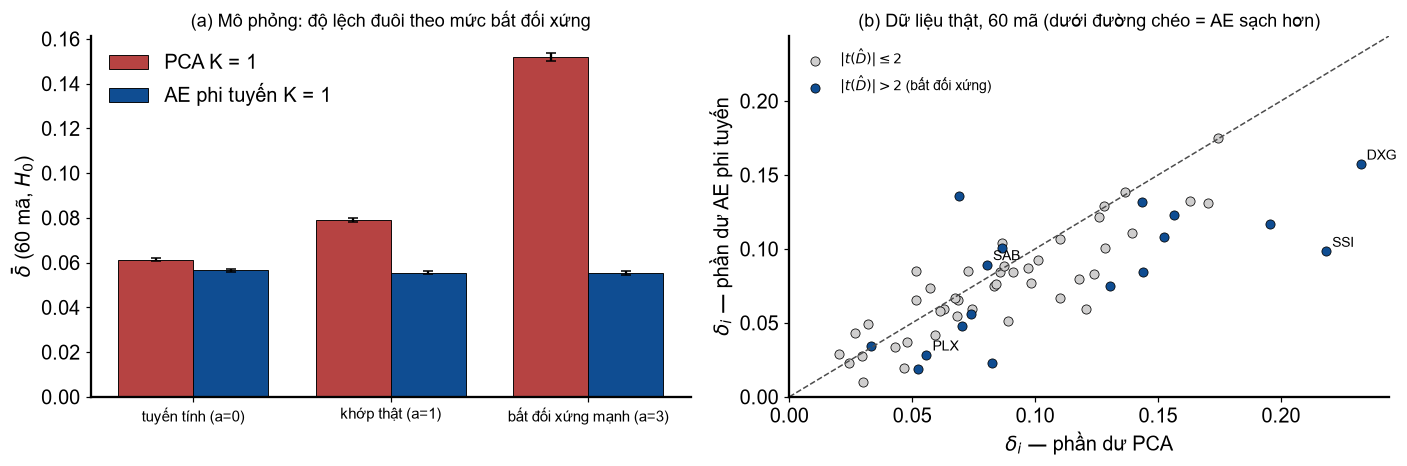

,psi_TB,cung_nganh,khac_nganh,5_dau,3_cuoi
AE phi tuyến K=1 (60 mã),0.546,0.577,0.541,MSN → FRT → DGC → MWG → CTD,DCM → MBB → CTG
PCA K=1 (60 mã),0.545,0.577,0.540,MSN → HAG → FRT → DGC → MWG,BID → DPM → DCM
"PCA K=1 (Kendall, trong mẫu)",0.545,0.578,0.540,MSN → HAG → DXG → FRT → CII,CTG → DPM → DCM
Có điều kiện thị trường,0.552,0.603,0.544,SAB → FRT → TCM → VJC → HDG,VPB → SSI → HCM


In [6]:
sim4 = read("04_nonlinear_sim")
gm4 = read("04_residual_market_tail", index_col=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
scen = list(dict.fromkeys(sim4.kich_ban))
d = sim4[sim4.gia_thuyet == "H0"].groupby(["kich_ban", "phuong_phap"]).delta_duoi.agg(["mean", "sem"])
x = np.arange(len(scen)); w = 0.38
for j, (m, lab, c) in enumerate([("pca1", "PCA K = 1", PAL["red_strong"]), ("nl1", "AE phi tuyến K = 1", PAL["blue_main"])]):
    dd = d.xs(m, level=1).reindex(scen)
    axes[0].bar(x + (j - 0.5) * w, dd["mean"], w, yerr=dd["sem"], color=c, edgecolor="black", lw=0.6, capsize=3, label=lab)
axes[0].set_xticks(x, scen, fontsize=10); axes[0].set_ylabel(r"$\bar\delta$ (60 mã, $H_0$)"); axes[0].legend()
axes[0].set_title("(a) Mô phỏng: độ lệch đuôi theo mức bất đối xứng", fontsize=12)
strong = gm4["t_D"].abs() > 2
ax = axes[1]
ax.scatter(gm4.loc[~strong, "dev_PCA"], gm4.loc[~strong, "dev_AE"], color=PAL["neutral"], edgecolor="black", lw=0.5,
           label=r"$|t(\hat D)| \leq 2$")
ax.scatter(gm4.loc[strong, "dev_PCA"], gm4.loc[strong, "dev_AE"], color=PAL["blue_main"], edgecolor="black", lw=0.5,
           label=r"$|t(\hat D)| > 2$ (bất đối xứng)")
lim = [0, gm4[["dev_PCA", "dev_AE"]].max().max() * 1.05]
ax.plot(lim, lim, ls="--", color=PAL["gray_dark"], lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
for s in ["SSI", "DXG", "SAB", "PLX"]:
    ax.annotate(s, (gm4.loc[s, "dev_PCA"], gm4.loc[s, "dev_AE"]), xytext=(4, 3), textcoords="offset points", fontsize=9)
ax.set_xlabel(r"$\delta_i$ — phần dư PCA"); ax.set_ylabel(r"$\delta_i$ — phần dư AE phi tuyến"); ax.legend(fontsize=9, loc="upper left")
ax.set_title("(b) Dữ liệu thật, 60 mã (dưới đường chéo = AE sạch hơn)", fontsize=12)
U.finalize_figure(fig, "finding_5_nonlinear_factor", folder=FOLDER); plt.show()
read("04_real_ease", index_col=0)[["psi_TB", "cung_nganh", "khac_nganh", "5_dau", "3_cuoi"]]

### Phân tích
- **Phi tuyến có thật:** hệ số tải khi thị trường giảm khác khi tăng ở 17/60 mã (kỳ vọng ≈ 3 nếu không có), theo hai chiều: chứng khoán và DXG tăng mạnh hơn chiều lên,
  nhóm phòng thủ, dầu khí, cảng biển chủ yếu theo chiều xuống (SAB, PLX, VHC, PVT).
- **$R^2$ không đổi:** AE tuyến tính trùng PCA (Mệnh đề 1 của Gu và cs.), AE phi tuyến bằng PCA (0,342) — đúng kết luận "không hơn tuyến tính" của Spilak & Härdle.
  AE ReLU không âm của Spilak & Härdle bỏ sót cú sập chung ($R^2$ đuôi dưới 0,714 so với 0,752).
- **Nhưng phần dư sạch đuôi hơn:** mô phỏng — $\bar\delta$ của PCA tăng 0,061 → 0,152 theo mức bất đối xứng, của AE giữ 0,056–0,057, SID ngang phương pháp tốt nhất;
  dữ liệu thật — ở 17 mã bất đối xứng $\bar\delta$ giảm 0,116 → 0,084 (Wilcoxon $p$ = 0,003), toàn 60 mã 0,094 → 0,077.
- **EASE gần như không đổi** (đồng thuận 0,92 với PCA, 0,74 với hệ số có điều kiện): phụ thuộc đuôi còn lại vẫn trong ngành hẹp; gợi ý chiều MBB → TCB → VPB trong khối ngân hàng.

## Kết luận Calibration
1. Quy trình hiệu chỉnh: GARCH-t (kết quả vững với dạng GARCH) → khử một nhân tố thị trường (PCA/LOO, hoặc AE hệ số tải phi tuyến để phần dư sạch đuôi hơn) → EASE với
   $k = \lfloor n^{0,35}\rfloor$ → bổ sung Granger trong đuôi với ngưỡng hiệu chỉnh bằng mô phỏng.
2. Sau hiệu chỉnh: lan truyền đồng thời **không xác định được chiều** chắc chắn giữa các mã (phụ thuộc còn lại là trong ngành hẹp; vài gợi ý "mã đầu ngành → mã nhỏ cùng ngành");
   lan truyền **theo ngày** ở trễ 1 phổ biến hơn với 60 mã nhưng nghiêng về mã kém thanh khoản — cần tách khỏi trễ do thanh khoản.
3. Với 60 mã, lợi thế của hệ số có điều kiện biến mất; khử nhân tố bằng AE hệ số tải phi tuyến giữ SID ngang các phương pháp tuyến tính và làm phần dư sạch đuôi hơn ở mã bất đối xứng.
4. Hướng tiếp theo: kiểm soát thanh khoản/giao dịch không đồng bộ trong Granger trong đuôi và kiểm chứng ngoài mẫu; nhân tố ngành hẹp (chứng khoán, thép, phân bón) trong mô hình nhân tố.